# 1.0 - Spatio-Temporal Data Wrangling
**Week 1** | Axlero DA Internship - Project 3: Delivery Route Delay Forecasting

**Goal:** pull shipments from PostgreSQL, parse messy datetime strings, compute delivery duration in hours, calculate **Haversine** distances from raw coordinates with the `math` module, and audit data quality.

**Business question:** can we trust the timestamps and coordinates enough to say *how late* a shipment really was?

In [1]:
import sys, warnings
sys.path.append("..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src import config, features as F
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
def save(name):
    config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    plt.savefig(config.FIGURES_DIR / name, dpi=140, bbox_inches="tight")


## 1. Load from PostgreSQL
`sql/02_extract_shipments.sql` removes exact duplicates on the SQL side. Timestamps arrive as **text** in mixed formats.

In [2]:
raw = F.load_raw_shipments()
print(raw.shape, '| rows in DB table:', raw.attrs['rows_in_db'])
raw.head()

(30000, 13) | rows in DB table: 30120


,shipment_id,carrier_id,vehicle_type,origin_city,origin_lat,origin_lon,dest_city,dest_lat,dest_lon,package_weight_kg,sla_hours,dispatch_time,delivery_time
0,100001,C05,van,Chennai,13.0827,80.2707,Hyderabad,17.43721,78.51079,4.73,32.0,2024-12-09 12:26:00,2024-12-10 15:54:58
1,100002,C02,van,Hyderabad,17.3850,78.4867,Hyderabad,17.27691,78.46106,56.06,6.0,2024-11-17 16:25:00,2024-11-17 21:16:52
2,100003,C07,mini_truck,Kolkata,22.5726,88.3639,Kolkata,22.56960,88.40925,96.00,6.0,2025-03-24 23:16:00,2025-03-25 03:35:56
3,100004,C05,van,Delhi,28.7041,77.1025,Chandigarh,30.69549,76.67992,20.61,12.0,2025-01-07 15:47:00,08 Jan 2025 02:08 AM
4,100005,C07,van,Bengaluru,12.9716,77.5946,Bengaluru,12.98299,77.52221,34.62,6.0,2025-12-15T17:13:00Z,2025-12-15T20:42:29Z


In [3]:
print(raw[['dispatch_time','delivery_time']].sample(8, random_state=1).to_string())
print('\nvehicle_type labels:', sorted(raw.vehicle_type.unique()))

              dispatch_time         delivery_time
10747   2025-07-25 13:09:00  2025-07-27T12:01:20Z
12573   2024-06-29 15:57:00  29 Jun 2024 09:25 PM
29676  11 Apr 2024 08:45 AM  2024-04-13T19:32:46Z
8856    2025-09-29 03:29:00   2025-10-01 06:41:22
21098   2025-09-15 10:08:00   2025-09-18 04:54:23
17458  22 Sep 2024 03:36 PM   2024-09-23 22:55:16
1476    2024-10-21 21:39:00  2024-10-25T19:43:50Z
5120    2025-08-11 16:08:00   2025-08-14 22:50:47

vehicle_type labels: [' bike', ' mini_truck', ' truck', ' van', 'BIKE', 'Bike', 'MINI_TRUCK', 'Mini Truck', 'TRUCK', 'Truck', 'VAN', 'Van', 'bike', 'mini_truck', 'truck', 'van']


## 2. Quality audit (before touching anything)

In [4]:
audit_raw = pd.DataFrame({'missing': raw.isna().sum(), 'pct': (raw.isna().mean()*100).round(2)})
print(audit_raw[audit_raw.missing > 0])
lat_bad = ~raw.dest_lat.astype(float).between(*F.INDIA_LAT); print('\nDestination latitudes outside India:', int(lat_bad.sum()))

                   missing  pct
carrier_id             150  0.5
package_weight_kg      450  1.5

Destination latitudes outside India: 389


## 3. Parse complex datetime strings
Four formats are mixed in the same column. Each **explicit** format is tried in turn (explicit formats remove the `05/03/2024` day-vs-month ambiguity).

In [5]:
d = F.parse_mixed_datetimes(raw.dispatch_time); v = F.parse_mixed_datetimes(raw.delivery_time)
print('unparsed dispatch:', int(d.isna().sum()), '| unparsed delivery:', int(v.isna().sum()))
print('delivery BEFORE dispatch:', int((v < d).sum()))
raw_dur = (v - d).dt.total_seconds()/3600
print('absurd durations (> 30 days):', int((raw_dur > 720).sum()))

unparsed dispatch: 0 | unparsed delivery: 0
delivery BEFORE dispatch: 240
absurd durations (> 30 days): 46


## 4. Clean programmatically (`F.clean_shipments`)
| Issue | Fix |
|---|---|
| duplicates | removed |
| delivery before dispatch | timestamps swapped |
| year typo (2025 -> 2026) | corrected by -1 year when the result is plausible |
| lat/lon transposed | swapped back |
| impossible coordinates | replaced by the destination-city median |
| missing weight | median of vehicle type |
| vehicle label casing | normalised |
| missing carrier | `UNKNOWN` |

In [6]:
clean, audit = F.clean_shipments(raw)
for k, v in audit.items(): print(f'{k:30s}{v}')
print('\nIntegrity (< 5% rows dropped):', 'PASS' if audit['pct_rows_dropped'] < 5 else 'FAIL')

rows_raw                      30120
sql_duplicates_removed        120
unparseable_timestamps        0
missing_carrier               150
missing_weight                450
coords_swapped_fixed          299
coords_imputed_from_city      90
timestamps_swapped_fixed      240
year_typos_fixed              46
unfixable_dropped             0
rows_clean                    30000
pct_rows_dropped              0.398

Integrity (< 5% rows dropped): PASS


## 5. Delivery duration and Haversine distance
`hours_delayed = delivery_hours - sla_hours` (negative = early). `distance_km` uses `math.sin/cos/asin/sqrt` on raw coordinates.

In [7]:
print(round(F.haversine_km(19.0760, 72.8777, 28.7041, 77.1025)), 'km Mumbai -> Delhi (sanity check: ~1,150 km great-circle)')
clean[['shipment_id','origin_city','dest_city','distance_km','sla_hours','delivery_hours','hours_delayed','is_late']].head()

1153 km Mumbai -> Delhi (sanity check: ~1,150 km great-circle)


,shipment_id,origin_city,dest_city,distance_km,sla_hours,delivery_hours,hours_delayed,is_late
0,101603,Mumbai,Mumbai,16.695334,4.0,3.883333,-0.116667,0
1,113774,Kolkata,Kolkata,8.427066,8.0,4.959444,-3.040556,0
2,101573,Ahmedabad,Ahmedabad,13.341778,6.0,4.753056,-1.246944,0
3,129083,Kolkata,Kolkata,7.577145,6.0,4.234167,-1.765833,0
4,119631,Mumbai,Pune,116.357356,8.0,6.233333,-1.766667,0


In [8]:
import json
clean.to_csv(config.DATA_INTERIM / 'shipments_clean.csv', index=False)
(config.DATA_INTERIM / 'cleaning_audit.json').write_text(json.dumps(audit, indent=2))
print(clean.shape)

(30000, 17)


## 6. Initial distributions

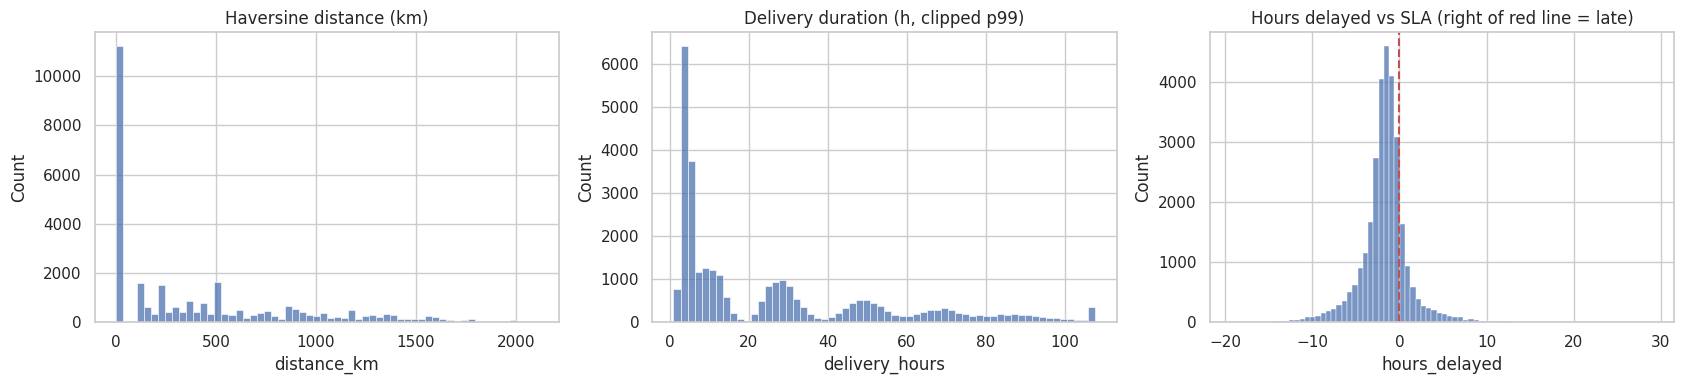

Late shipments: 17.1%


In [9]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(clean.distance_km, bins=60, ax=ax[0]); ax[0].set_title('Haversine distance (km)')
sns.histplot(clean.delivery_hours.clip(upper=clean.delivery_hours.quantile(.99)), bins=60, ax=ax[1]); ax[1].set_title('Delivery duration (h, clipped p99)')
sns.histplot(clean.hours_delayed, bins=80, ax=ax[2]); ax[2].axvline(0, c='r', ls='--'); ax[2].set_title('Hours delayed vs SLA (right of red line = late)')
plt.tight_layout(); save('01_distributions.png'); plt.show()
print(f'Late shipments: {clean.is_late.mean():.1%}')

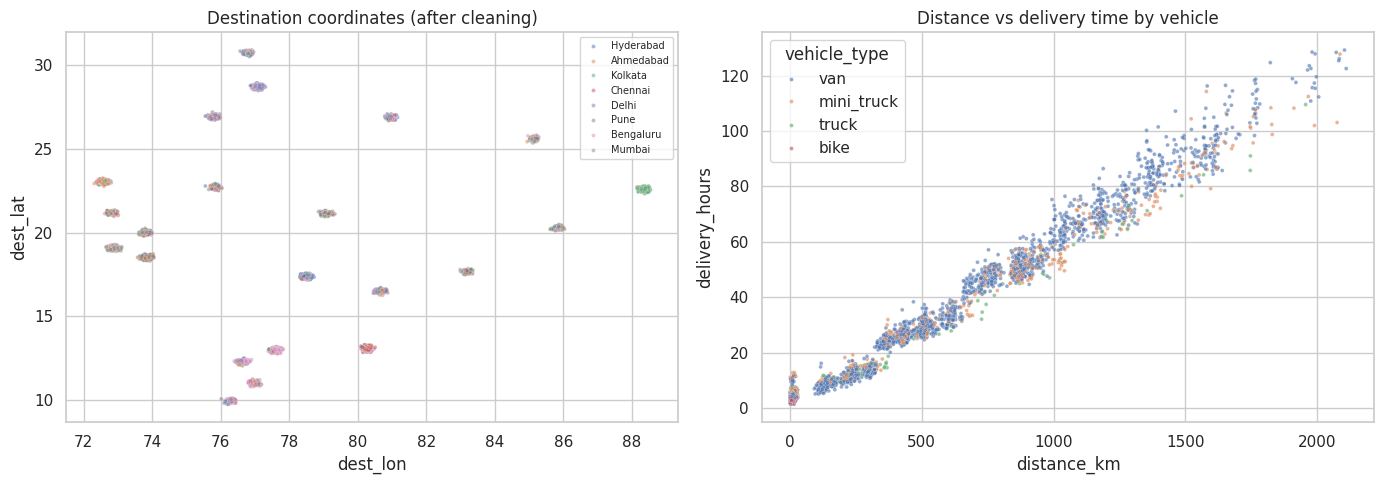

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
s = clean.sample(4000, random_state=0)
sns.scatterplot(data=s, x='dest_lon', y='dest_lat', hue='origin_city', s=8, alpha=.5, ax=ax[0]); ax[0].set_title('Destination coordinates (after cleaning)'); ax[0].legend(fontsize=7)
sns.scatterplot(data=s, x='distance_km', y='delivery_hours', hue='vehicle_type', s=8, alpha=.6, ax=ax[1]); ax[1].set_title('Distance vs delivery time by vehicle')
plt.tight_layout(); save('02_geo_and_distance.png'); plt.show()

## Findings
* Mixed timestamp formats, swapped timestamps, year typos and transposed coordinates were all repaired - **under 0.5 % of rows dropped** (target < 5 %).
* Distance is the main driver of duration, but lateness is measured against the SLA, so it depends on more than distance.

**Next:** time-series EDA and weather enrichment (2.0).